In [17]:
import os
import sys

import joblib
import itertools
import pandas as pd
import numpy as np
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, '../../..')
from utils.plotting import plot_movement_data
from utils.metrics import show_feature_extraction_metrics
from utils.constants import Configs
from utils.loso_pipeline import run_loso_evaluation
from utils.loso_models.ocsvm_detector import OCSVMDetector
from utils.helper_functions import calculate_trash_percentage
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.feature_selection import make_corr_filter

TARGET_MOVEMENT = 'Move'
ALGORITHM_NAME = 'OCSVM'
MODEL_REPRESENTATION = 'FeatureBased'

EXTRACT_SCORES = True

In [18]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [19]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID', 'movID'])
total_known_outliers = len(outliers_csv)

# Filter the outliers for the target movement
outliers_csv = outliers_csv[outliers_csv['movLabel'] == TARGET_MOVEMENT].reset_index(drop=True)
total_target_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
print(f"Total target outliers: {total_target_outliers}")
outliers_csv.head()

Total known outliers: 18
Total target outliers: 5


,sub,repID,movID,movLabel
0,2,2,9,Move
1,4,1,9,Move
2,7,1,9,Move
3,11,1,9,Move
4,12,1,9,Move


### Load Features from csv

In [20]:
cache_path = Configs.wrist_only_feature_extraction_features(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Features for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")

features_df = joblib.load(cache_path)
features_df = features_df.sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)
X_features = features_df[Configs.FEATURE_COLS].to_numpy()

assert not np.isnan(X_features).any(), "NaN in features"

## One Class SVM With Feature Extraction

In [21]:
total_trials_unique = features_df.drop_duplicates(subset=['sub', 'repID'])
total_trials = len(total_trials_unique)
total_samples = len(features_df)
known_outlier_rate = (total_target_outliers / total_samples) if total_samples > 0 else 0.0
percentagem_conhecida = known_outlier_rate * 100

print(f"--- Preparation (Feature-Based) ---")
print(f"Total samples analyzed ({TARGET_MOVEMENT}): {total_samples}")
print(f"Total unique repetitions analyzed ({TARGET_MOVEMENT}): {total_trials}")
print(f"Minimum confirmed outlier rate in CSV (sub + repID): {percentagem_conhecida:.2f}%")

--- Preparation (Feature-Based) ---
Total samples analyzed (Move): 95
Total unique repetitions analyzed (Move): 95
Minimum confirmed outlier rate in CSV (sub + repID): 5.26%


In [22]:
percentagem_conhecida

5.263157894736842

### Grid Search

In [ ]:
min_nu = 0.01 
max_nu = known_outlier_rate + 0.10            
nu_range = np.linspace(min_nu, max_nu, 15)
nu_range = [round(n, 3) for n in nu_range] 

gamma_options = ['scale', 'auto', 0.01, 0.1, 1] 
results_log = []

param_grid = [
    {'nu': n, 'gamma': g} 
    for n, g in itertools.product(nu_range, gamma_options)
]

loso_results = run_loso_evaluation(
    detector_class=OCSVMDetector, 
    param_grid=param_grid,
    data_matrix=X_features,
    metadata_df=features_df[Configs.META_COLS],
    known_outliers_df=outliers_csv,
    metric_type='euclidean',
    scale_features=True,
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    feature_filter=make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP),
)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 

### Statistic Evaluation - Bootstraping

In [24]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [25]:
append_experiment_record(
    summary_path=Configs.WRIST_ONLY_FEATURE_EXTRACTION_SUMMARY_FILE,
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=total_samples,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for OCSVM - FeatureBased - Move - 95 Movements (MOVEMENT-level):
Unique Outliers Detected: 21
Rejection Rate: 22.11%
Known Positives in Ground Truth: 5
------------------------------
Total True Positives (Global):  3
Total False Positives (Global): 18
Total False Negatives (Global): 2
Total True Negatives (Global):  72
------------------------------
Blind Precision: 14.29 [0.00–27.27]
Blind Recall:    60.00 [0.00–100.00]
Blind F1-Score:  23.08
Blind F2-Score:  36.59 [0.00–57.17]
Blind MCC:       0.22 [-0.06–0.40]
Blind AUPRC:  64.13 [5.26–100.00]
Blind AUROC:   75.11

Total Tuning Time (19 Subjects): 8.7641s
Total Inference Time (19 Subjects): 0.0139s

Overall Best Parameters (Most frequent across folds):
   {'gamma': 0.01, 'nu': np.float64(0.112)}
Occurrences: 2


## Train Final Model

In [ ]:
best_params = loso_results['Best_Params']
nu = best_params['nu']
gamma = best_params['gamma']

final_filter = make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP)
X_final, dropped = final_filter(X_features, np.arange(len(X_features)))
print("Dropped features:", dropped)

X_features_scaled_full = StandardScaler().fit_transform(X_final)

In [ ]:
ocsvm_final = OneClassSVM(kernel='rbf', nu=best_params['nu'], gamma=best_params['gamma'])

# Train mode (oultier = -1, normal = 1)
labels = ocsvm_final.fit_predict(X_features_scaled_full)
features_df['anomaly'] = labels
joblib.dump(ocsvm_final, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

Raw Outlier Trials Detected: 10
Unique Outlier Trials Detected: 10
Detected Outlier Percentage (sub + repID + movID): 10.53%
Detected Outlier Percentage (sub + repID): 10.53%


In [ ]:
# Results
n_outliers = (features_df['anomaly'] == -1).sum()
outliers_details = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

n_unique_outliers, correct_trash_pct = calculate_trash_percentage(features_df, total_trials)
print(f"Raw Outlier Trials Detected: {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Detected Outlier Percentage (sub + repID + movID): {(n_outliers/total_trials*100):.2f}%")
print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

In [28]:
cols_to_extract = ['sub', 'repID', 'movID']
outliers_metadata_df = features_df.loc[outliers_details.index, cols_to_extract].copy()
print("Outliers metadata:")
print(outliers_metadata_df)

Outliers metadata:
    sub  repID  movID
6     2      2      9
7     2      3      9
8     2      4      9
10    3      1      9
15    4      1      9
50   11      1      9
52   11      3      9
55   12      1      9
84   17      5      9
90   19      1      9


In [29]:
identified_unique = outliers_metadata_df.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = show_feature_extraction_metrics(
    features_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 4
False Positives (Identified, not in CSV): 6
False Negatives (In CSV, not identified): 1
True Negatives (Normal, stayed normal): 84
--------------------------------------------------
Missing outliers (In CSV, not identified):
   sub  repID
2    7      1

Precision (False Positives): 4/10 (40.00%)
Recall (True Positive Rate): 4/5 (80.00%)
F1-Score: 53.33%
F2-Score: 66.67%


O código abaixo serve para criar as variáveis que existiam antes do refactor para cirar os gráficos. Não quero mexer muito na forma como os gráficos são montados para evitar problemas.

In [30]:
outlier_ids = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

# Create a "unique key" to facilitate filtering
features_df['key'] = features_df['sub'].astype(str) + '_' + features_df['repID'].astype(str) + '_' + features_df['movID'].astype(str)
outlier_keys = features_df[features_df['anomaly'] == -1]['key'].tolist()

# Return to the original DataFrame for plotting
# Create a temporary key in the original df as well
df['temp_key'] = df['sub'].astype(str) + '_' + df['repID'].astype(str) + '_' + df['movID'].astype(str)

# Separate visually
# Note: This is only for plotting; it does not permanently alter the original df if you do not want it to
df_outliers = df[df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]
df_clean = df[~df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]


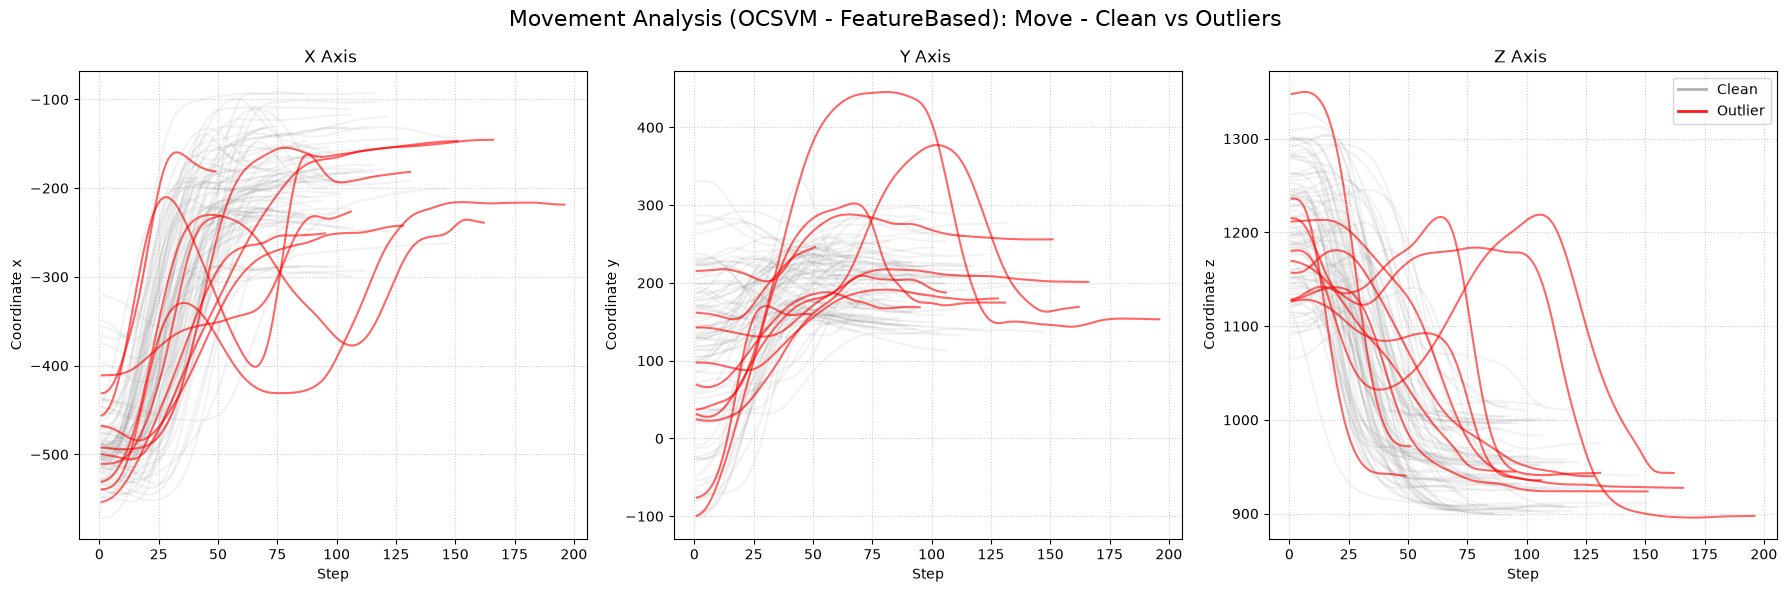

In [31]:
plot_movement_data(
    clean_data=df_clean,
    outlier_data=df_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)

In [32]:
df.drop(columns=['temp_key'], inplace=True)